# Mudcard
- **Doesn't k nearest neighbors have a weight parameter?**
    - yes but it doesn't weight the nearest neighbors with respect to the classification label but with respect to how far a nearest neighbor is from the point you are trying to predict
- **For imbalanced, is the model only worth it if the metrics are above 99% for example, since the baseline in real data (assuming its 99% to 1% balance) is going to be 99%?**
    - Correct.
    - If accuracy is your evaluation metric, a model is only worth considering for deployment if its accuracy is above the baseline.
    - Otherwise what's the point? Your accuracy would be higher if you predicted class 0 to all points
- **is it ever worth resampling/rebalancing?**
    - yes, absolutely but only if resampling improves the model's performance on the original class distribution


# Non-linear ML algorithms - Support Vector Machines
By the end of this lecture, you will be able to
- Describe how linear SVMs work and what support vectors are
- Apply non-linear SVMs with radial basis functions (gaussian kernel)
- Discuss what secondary considerations might go into selecting/excluding ML models

# <font color='LIGHTGRAY'>Non-linear ML algorithms - Support vector machines</font>
<font color='LIGHTGRAY'>By the end of this lecture, you will be able to</font>
- **Describe how linear SVMs work and what support vectors are**
- <font color='LIGHTGRAY'>Apply non-linear SVMs with radial basis functions (gaussian kernel)</font>
- <font color='LIGHTGRAY'>Discuss what secondary considerations might go into selecting/excluding ML models</font>

## Linear Support Vector Machines
- let's consider a simple binary classification problem with two features
- the two classes are linearly separable meaning that you can find a linear decision boundary which gives 0 error on the training set
- here is an example:

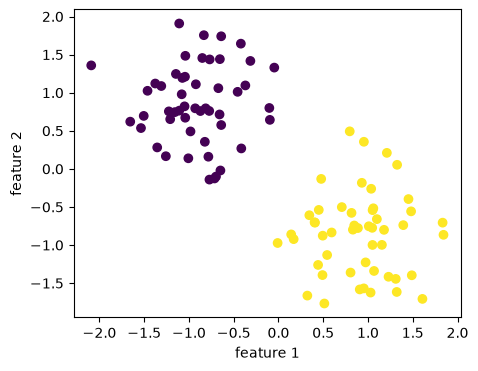

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler


X_train, y_train = make_blobs(n_samples=100, n_features = 2, centers = 2, cluster_std = 2, random_state = 42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)

plt.figure(figsize=(5,4))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train)
plt.xlabel('feature 1')
plt.ylabel('feature 2')
plt.show()

Based on the logistic regression lecture, we can draw linear decision boudnaries for this dataset.

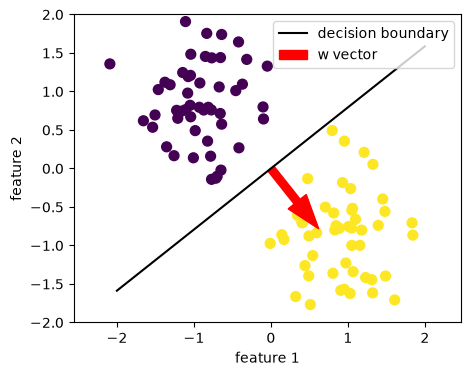

In [2]:
# create the w vector:
w = np.zeros([2])

phi = -0.9 # [radians] any value between -0.1 and -0.9 gives 0 loss on the training data!
length = 1

w[0] = np.cos(phi)*length
w[1] = np.sin(phi)*length

# calculate the decision boundary - it's a line perpendicular to the w vector
a = -w[0] / w[1]
xx = np.linspace(-2, 2)
yy = a * xx

plt.figure(figsize=(5,4))
plt.axis('equal')
plt.ylim((-2,2))
# visualize the decision boundary
plt.plot(xx, yy, "k-",label='decision boundary')

# add the datapoints
plt.scatter(X_train[:,0],X_train[:,1],c=y_train,s=50)
plt.xlabel('feature 1')
plt.ylabel('feature 2')

# add the w vector
plt.arrow(0,0,w[0],w[1],width=0.1,length_includes_head=True,color='r',label='w vector')
plt.legend()
plt.show()

- any phi between -0.1 and -0.9 radians give a 0 loss on the training data!
- which one should we choose?
- not all decision boundaries are created equal!
- margin helps us answer this question

## Margin
- the minimum distance between any training point and the decision boundary
- light blue region on the figures

<center><img src = '../figures/margin_example1.png' width="350"><img src = '../figures/margin_example2.png' width="350"></center>

- out of the inifnite number of decision boundaries we could choose, we want one that maximizes the margin (example 2 in this case)!
- this is the key idea of a support vector machine


## What are the support vectors?
- **The support vectors are data points that define the margin**
- each data point is a vector in the feature space
- the points that 'support' or define the margin are the support vectors
- the other points don't matter because the decision boundary and the margin are only impacted by the support vectors!
- let's visualize the linear SVM and the support vectors on the toy dataset:

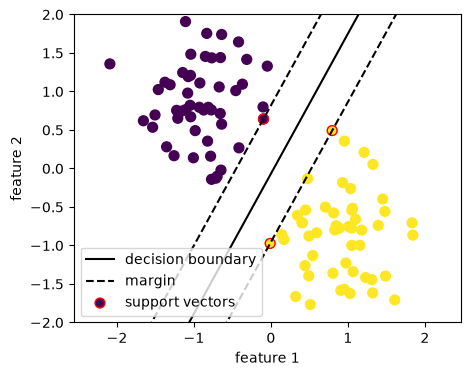

In [3]:
from sklearn.svm import SVC

clf = SVC(kernel='linear',C=1e10) # linear SVM with no or very little regularization (C = 1 / regularization strength)
clf.fit(X_train,y_train)

plt.figure(figsize=(5,4))
plt.axis('equal')

# get the separating hyperplane
w = clf.coef_[0] # this is the w vector
a = -w[0] / w[1]
xx = np.linspace(-2, 2)
yy = a * xx - (clf.intercept_[0]) / w[1]

# plot the parallels to the separating hyperplane that pass through the
# support vectors (margin away from hyperplane in direction
# perpendicular to hyperplane). This is sqrt(1+a^2) away vertically in
# 2-d.
margin = 1 / np.sqrt(np.sum(clf.coef_**2))
yy_down = yy - np.sqrt(1 + a**2) * margin
yy_up = yy + np.sqrt(1 + a**2) * margin

plt.ylim((-2,2))
plt.plot(xx, yy, "k-",label='decision boundary')
plt.plot(xx, yy_down, "k--",label='margin')
plt.plot(xx, yy_up, "k--")

# add the datapoints
plt.scatter(X_train[:,0],X_train[:,1],c=y_train,s=50)
# clf.support_ is the indices of the support vectors!
plt.scatter(X_train[clf.support_,0],X_train[clf.support_,1],c=y_train[clf.support_],s=50,edgecolors='r',label= 'support vectors')
plt.xlabel('feature 1')
plt.ylabel('feature 2')
plt.legend(loc=3)
plt.show()



## Quiz 1

How many support vectors are there in the example below?

<center><img src = '../figures/margin_example3.png' width="450"></center>


# <font color='LIGHTGRAY'>Non-linear ML algorithms - Support vector machines</font>
<font color='LIGHTGRAY'>By the end of this lecture, you will be able to</font>
- <font color='LIGHTGRAY'>Describe how linear SVMs work and what support vectors are</font>
- **Apply non-linear SVMs with radial basis functions (gaussian kernel)**
- <font color='LIGHTGRAY'>Discuss what secondary considerations might go into selecting/excluding ML models</font>

# Non-linear SVMs
- non-linear SVMs are an extension of linear SVMs
- The idea is to map or embed the data points into a higher (sometimes infinite) dimensional feature space where the problem is linearly separable
    - think polynomial regression in lecture 8!
- We train a linear SVM in this higher dimensional space
- It can be very computationally expensive to perform feature transformations and to train a linear SVM in a very high dimensional space.
    - if the feature space is infinite dimensional, this is in fact impossible to do computationally
- A mathematical trick called the **kernel trick** is applied to perform these operations in a computationally efficient manner
- the math is pretty complex and beyond this course
- recommend CSCI1420 or DATA2060 to dive deeper into ML algorithms
- If you don't plan to take those courses but want to learn more, check out [this post](https://medium.com/data-science/the-kernel-trick-c98cdbcaeb3f) for a high level overview

## Gaussian SVMs
- SVM with a Gaussian or radial basis function kernel
- popular choice among possible non-linear SVM kernels
- this kernel basically smoothes datapoints to multi-dimensional gaussians

### SVM in regression

In [4]:
import numpy as np
from sklearn.svm import SVR
np.random.seed(10)
def true_fun(X):
    return np.cos(1.5 * np.pi * X)

n_samples = 30

X = np.random.rand(n_samples)
y = true_fun(X) + np.random.randn(n_samples) * 0.1

X_new = np.linspace(-0.5, 1.5, 2000)

reg = SVR(gamma = 1, C = 1)
reg.fit(X[:, np.newaxis],y)
y_new = reg.predict(X_new[:, np.newaxis])


In [5]:
help(SVR)

Help on class SVR in module sklearn.svm._classes:

class SVR(sklearn.base.RegressorMixin, sklearn.svm._base.BaseLibSVM)
 |  SVR(
 |      *,
 |      kernel='rbf',
 |      degree=3,
 |      gamma='scale',
 |      coef0=0.0,
 |      tol=0.001,
 |      C=1.0,
 |      epsilon=0.1,
 |      shrinking=True,
 |      cache_size=200,
 |      verbose=False,
 |      max_iter=-1
 |  )
 |
 |  Epsilon-Support Vector Regression.
 |
 |  The free parameters in the model are C and epsilon.
 |
 |  The implementation is based on libsvm. The fit time complexity
 |  is more than quadratic with the number of samples which makes it hard
 |  to scale to datasets with more than a couple of 10000 samples. For large
 |  datasets consider using :class:`~sklearn.svm.LinearSVR` or
 |  :class:`~sklearn.linear_model.SGDRegressor` instead, possibly after a
 |  :class:`~sklearn.kernel_approximation.Nystroem` transformer or
 |  other :ref:`kernel_approximation`.
 |
 |  Read more in the :ref:`User Guide <svm_regression>`.
 

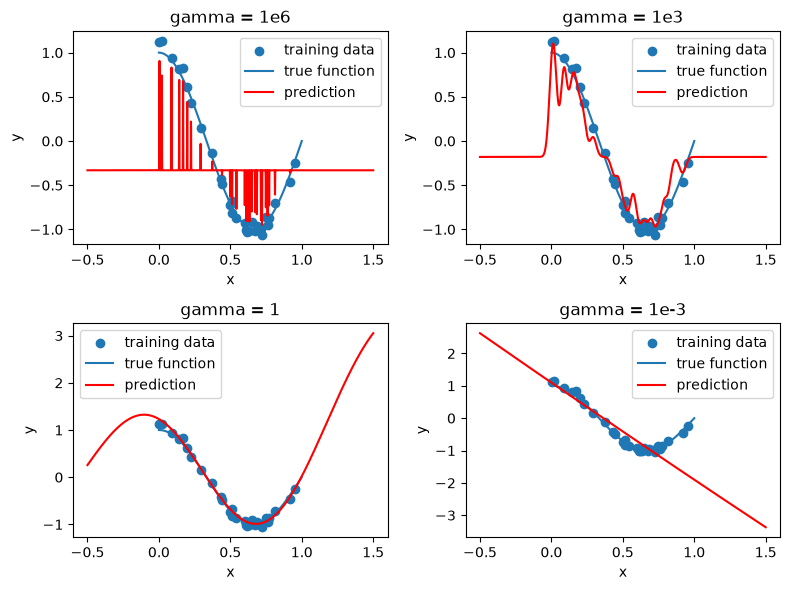

In [6]:
import matplotlib.pyplot as plt
import matplotlib


plt.figure(figsize=(8,6))

plt.subplot(2,2,1)
plt.scatter(X,y,label='training data')
plt.plot(np.linspace(0, 1, 100),true_fun(np.linspace(0, 1, 100)),label='true function')
reg = SVR(gamma = 1000000, C = 1e4)
reg.fit(X[:, np.newaxis],y)
y_new = reg.predict(X_new[:, np.newaxis])
plt.plot(X_new,y_new,'r',label='prediction')
plt.xlabel('x')
plt.ylabel('y')
plt.title('gamma = 1e6')
plt.legend()

plt.subplot(2,2,2)
plt.scatter(X,y,label='training data')
plt.plot(np.linspace(0, 1, 100),true_fun(np.linspace(0, 1, 100)),label='true function')
reg = SVR(gamma = 1000, C = 1e4)
reg.fit(X[:, np.newaxis],y)
y_new = reg.predict(X_new[:, np.newaxis])
plt.plot(X_new,y_new,'r',label='prediction')
plt.xlabel('x')
plt.ylabel('y')
plt.title('gamma = 1e3')
plt.legend()

plt.subplot(2,2,3)
plt.scatter(X,y,label='training data')
plt.plot(np.linspace(0, 1, 100),true_fun(np.linspace(0, 1, 100)),label='true function')
reg = SVR(gamma = 1, C = 1e4)
reg.fit(X[:, np.newaxis],y)
y_new = reg.predict(X_new[:, np.newaxis])
plt.plot(X_new,y_new,'r',label='prediction')
plt.xlabel('x')
plt.ylabel('y')
plt.title('gamma = 1')
plt.legend()


plt.subplot(2,2,4)
plt.scatter(X,y,label='training data')
plt.plot(np.linspace(0, 1, 100),true_fun(np.linspace(0, 1, 100)),label='true function')
reg = SVR(gamma = 0.001, C = 1e4)
reg.fit(X[:, np.newaxis],y)
y_new = reg.predict(X_new[:, np.newaxis])
plt.plot(X_new,y_new,'r',label='prediction')
plt.xlabel('x')
plt.ylabel('y')
plt.title('gamma = 1e-3')
plt.legend()

plt.tight_layout()
plt.savefig('../figures/SVM_reg.png',dpi=300)
plt.show()


### SVM in classification

In [7]:
from sklearn.datasets import make_moons
import numpy as np
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV

# create the data
X,y = make_moons(noise=0.2, random_state=1,n_samples=200)
# set the hyperparameters
# NOTE: sklearn's SVC does not return predicted probabilities, only hard predictions!
# If you need an SVM with predicted probabilities, use CalibratedClassifierCV(SVC(...), ensemble=False)
clf = CalibratedClassifierCV(SVC(gamma = 1, C = 1), ensemble=False) # the default kernel is rbf
# fit the model
clf.fit(X,y)
# predict new data
#y_new = clf.predict(X_new)
# predict probabilities
#y_new = clf.predict_proba(X_new)

,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2","SVC(C=1, gamma=1)"
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",False
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'sigmoid'
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary <n_jobs>` for more details... versionadded:: 0.24",None
Name,Type,Value
"calibrated_classifiers_ calibrated_classifiers_: list (len() equal to cv or 1 if `ensemble=False`)The list of classifier and calibrator pairs.- When `ensemble=True`, `n_cv` fitted `estimator` and calibrator pairs. `n_cv` is the number of cross-validation folds.- When `ensemble=False`, the `estimator`, fitted on all the data, and fitted calibrator... versionchanged:: 0.24 Single calibrated classifier case when `ensemble=False`.",list,[<sklearn.cali...t 0x169295940>]
"classes_ cla

In [8]:
help(SVC)

Help on class SVC in module sklearn.svm._classes:

class SVC(sklearn.svm._base.BaseSVC)
 |  SVC(
 |      *,
 |      C=1.0,
 |      kernel='rbf',
 |      degree=3,
 |      gamma='scale',
 |      coef0=0.0,
 |      shrinking=True,
 |      probability='deprecated',
 |      tol=0.001,
 |      cache_size=200,
 |      class_weight=None,
 |      verbose=False,
 |      max_iter=-1,
 |      decision_function_shape='ovr',
 |      break_ties=False,
 |      random_state=None
 |  )
 |
 |  C-Support Vector Classification.
 |
 |  The implementation is based on libsvm. The fit time scales at least
 |  quadratically with the number of samples and may be impractical
 |  beyond tens of thousands of samples. For large datasets
 |  consider using :class:`~sklearn.svm.LinearSVC` or
 |  :class:`~sklearn.linear_model.SGDClassifier` instead, possibly after a
 |  :class:`~sklearn.kernel_approximation.Nystroem` transformer or
 |  other :ref:`kernel_approximation`.
 |
 |  The multiclass support is handled accordi

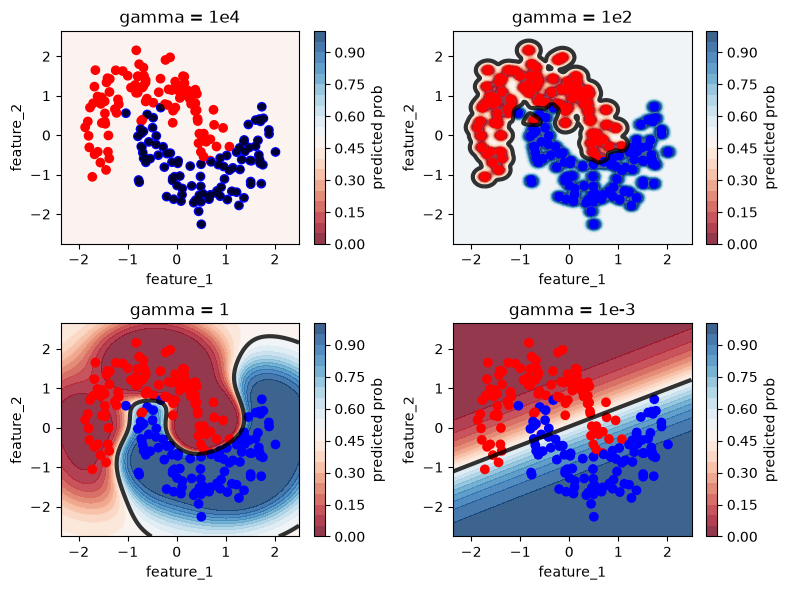

In [9]:
from sklearn.datasets import make_moons
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from matplotlib.colors import ListedColormap
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV

X = StandardScaler().fit_transform(X)

h = .02  # step size in the mesh

x_min, x_max = X[:, 0].min() - .5, X[:, 0].max() + .5
y_min, y_max = X[:, 1].min() - .5, X[:, 1].max() + .5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))

plt.figure(figsize=(8,6))
cm_bright = ListedColormap(['#FF0000', '#0000FF'])
cm = plt.cm.RdBu

plt.subplot(2,2,1)
clf = CalibratedClassifierCV(SVC(gamma = 1e4, C = 100), ensemble=False)
clf.fit(X,y)
Z = clf.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1]
# Put the result into a color plot
Z = Z.reshape(xx.shape)
plt.contourf(xx, yy, Z, cmap=cm, alpha=.8,vmin=0,vmax=1,levels=np.arange(0,1.05,0.05))
plt.colorbar(label='predicted prob')
plt.contour(xx, yy, Z, alpha=.8,vmin=0,vmax=1,levels=[0.5],colors=['k'],linewidths=3)
plt.scatter(X[:, 0], X[:, 1], c=y,cmap=cm_bright)
plt.xlabel('feature_1')
plt.ylabel('feature_2')
plt.title('gamma = 1e4')

plt.subplot(2,2,2)
clf = CalibratedClassifierCV(SVC(gamma = 1e2, C = 100), ensemble=False)
clf.fit(X,y)
Z = clf.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1]
# Put the result into a color plot
Z = Z.reshape(xx.shape)
plt.contourf(xx, yy, Z, cmap=cm, alpha=.8,vmin=0,vmax=1,levels=np.arange(0,1.05,0.05))
plt.colorbar(label='predicted prob')
plt.contour(xx, yy, Z, alpha=.8,vmin=0,vmax=1,levels=[0.5],colors=['k'],linewidths=3)
plt.scatter(X[:, 0], X[:, 1], c=y,cmap=cm_bright)
plt.xlabel('feature_1')
plt.ylabel('feature_2')
plt.title('gamma = 1e2')

plt.subplot(2,2,3)
clf = CalibratedClassifierCV(SVC(gamma = 1, C = 100), ensemble=False)
clf.fit(X,y)
Z = clf.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1]
# Put the result into a color plot
Z = Z.reshape(xx.shape)
plt.contourf(xx, yy, Z, cmap=cm, alpha=.8,vmin=0,vmax=1,levels=np.arange(0,1.05,0.05))
plt.colorbar(label='predicted prob')
plt.contour(xx, yy, Z, alpha=.8,vmin=0,vmax=1,levels=[0.5],colors=['k'],linewidths=3)
plt.scatter(X[:, 0], X[:, 1], c=y,cmap=cm_bright)
plt.xlabel('feature_1')
plt.ylabel('feature_2')
plt.title('gamma = 1')

plt.subplot(2,2,4)
clf = CalibratedClassifierCV(SVC(gamma = 1e-3, C = 100), ensemble=False)
clf.fit(X,y)
Z = clf.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1]
# Put the result into a color plot
Z = Z.reshape(xx.shape)
plt.contourf(xx, yy, Z, cmap=cm, alpha=.8,vmin=0,vmax=1,levels=np.arange(0,1.05,0.05))
plt.colorbar(label='predicted prob')
plt.contour(xx, yy, Z, alpha=.8,vmin=0,vmax=1,levels=[0.5],colors=['k'],linewidths=3)
plt.scatter(X[:, 0], X[:, 1], c=y,cmap=cm_bright)
plt.xlabel('feature_1')
plt.ylabel('feature_2')
plt.title('gamma = 1e-3')


plt.tight_layout()

plt.savefig('../figures/SVM_clf.png',dpi=300)
plt.show()




## Quiz 2

Bias variance trade off

Which gamma value gives the best trade off between high bias and high variance? Work through the steps to answer the question.

- Use random_state = 42 where-ever necessary.
- Split X, y into X_train, X_val, y_train, y_val such that 70% of the points are in train.
- Fit SVC models with C = 1, and gamma = 1e-3, 1e-2, 1e-1, 1e0, 1e1, 1e2, 1e3 on the training set.
- Measure the validation accuracy for each gamma.
- Which gamma value gives the highest validation accuracy?


In [10]:
# add your code here
X_train, y_train, X_val, y_val = train_test_split(X,y,train_size=0.7, random_state = 42)
gammas = [ 1e-3, 1e-2, 1e-1, 1e0, 1e1, 1e2, 1e3 ]

accuracies = []

for gamma in gammas:
    model = SVC(C=1,gamma=gamma)
    model.fit(X_train,y_train)
    accuracies.append(model.score(X_val,y_val))

best_indx = np.argmax(accuracies)
print("best accuracy:"accuracies[best_indx])
print("best gamma":gammas[best_indx])


# <font color='LIGHTGRAY'>Non-linear ML algorithms - Support vector machines</font>
<font color='LIGHTGRAY'>By the end of this lecture, you will be able to</font>
- <font color='LIGHTGRAY'>Describe how linear SVMs work and what support vectors are</font>
- <font color='LIGHTGRAY'>Apply non-linear SVMs with radial basis functions (gaussian kernel)</font>
- **Discuss what secondary considerations might go into selecting/excluding ML models**

## Which ML algorithm to try on your dataset?

- other than predictive power, what else is important for you?
   - is it suitable for large datasets? 
   - how the model behaves with respect to outliers?
   - does the prediction varies smoothly with the feature values?
   - can the model capture non-linear dependencies?
   - is the model easy to interpret for a human?
- here is a table to summarize things

| ML algo | suitable for large datasets? | behaviour wrt outliers | non-linear? | params to tune | smooth predictions | easy to interpret? |
| - | :-: | :-: | :-: | :-: | :-: | :-: |
| linear regression            	|              yes             	|linear extrapolation|      no     	| l1 and/or l2 reg 	| yes | yes|
| logistic regression          	|              yes             	|scales with distance from the decision boundary|      no     	| l1 and/or l2 reg 	| yes | yes|
| random forest regression     	|so so |constant|yes|max_features,  max_depth| no|so so|
| random forest classification 	|so so |step-like, difficult to tell|yes|max_features,  max_depth| no|so so|
| SVM rbf regression               	|no|non-linear extrapolation|yes|C, gamma|yes|so so|
| SVM rbf classification           	|no|50-50|yes|C, gamma|yes|so so|

- stakeholders will sometimes have special requests to include/exclude certain models
- i.e., I was told once to not even try tree-based algorithms on the dataset because they want a model that output smooth (meaning differentiable) predictions, not steps
- in certain domains (like banking) you might be limited to using interpretable models only (e.g., linear models or not too deep decision trees)

# Mudcard